___
<h1> Machine Learning </h1>
<h2> M. Sc. in Electrical and Computer Engineering </h2>
<h3> Instituto Superior de Engenharia / Universidade do Algarve </h3>

[MEEC](https://ise.ualg.pt/en/curso/1477) / [ISE](https://ise.ualg.pt) / [UAlg](https://www.ualg.pt)

Pedro J. S. Cardoso (pcardoso@ualg.pt)
___

# Feature engineering

Feature engineering is the process of transforming raw data into meaningful features that improve model performance. It includes creating, selecting, encoding, scaling, and combining variables to better capture patterns for the learning algorithm.

This notebook uses the wine quality data. Each row is a wine; `quality` is an integer score (typically 3 to 9).

That score can be read in two ways:

- **Classification:** predict which quality class the wine belongs to (3, 4, 5, …). That is what we do here.
- **Regression:** predict the score as a number, then perhaps round it.

Load the dataset into a pandas dataframe.


In [1]:
import pandas as pd
df = pd.read_csv('./data/winequalityN.csv')
df

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,white,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,white,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,white,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,white,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,red,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
6493,red,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,NaN,11.2,6
6494,red,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
6495,red,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


By calling the dataframe's `info` method, we can see that there are a few missing values.

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   object 
 1   fixed acidity         6487 non-null   float64
 2   volatile acidity      6489 non-null   float64
 3   citric acid           6494 non-null   float64
 4   residual sugar        6495 non-null   float64
 5   chlorides             6495 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6488 non-null   float64
 10  sulphates             6493 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


For treating missing values, please refer to the corresponding notebook were some techiniques are studied, here we will simply drop the rows with missing values.

In [3]:
df = df.dropna().reset_index(drop=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6463 entries, 0 to 6462
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6463 non-null   object 
 1   fixed acidity         6463 non-null   float64
 2   volatile acidity      6463 non-null   float64
 3   citric acid           6463 non-null   float64
 4   residual sugar        6463 non-null   float64
 5   chlorides             6463 non-null   float64
 6   free sulfur dioxide   6463 non-null   float64
 7   total sulfur dioxide  6463 non-null   float64
 8   density               6463 non-null   float64
 9   pH                    6463 non-null   float64
 10  sulphates             6463 non-null   float64
 11  alcohol               6463 non-null   float64
 12  quality               6463 non-null   int64  
dtypes: float64(11), int64(1), object(1)
memory usage: 656.5+ KB


## Categorical data transformation

Most machine learning algorithms cannot handle categorical data and, in our case, the `type` column is categorical. Therefore, categorical data must be transformed into numerical data. 

There are several ways to do the transformation, like:
- One-hot encoding -- transform each category into a binary column
- Ordinal encoding -- transform each category into a number
- Binary encoding -- transform each category into a binary number
- Hash encoding -- transform each category into a hash number
- ...

Let us see how to performe the first technique. 

### One hot encoding

One hot encoding is the process of converting a categorical feature into one or more binary (0/1) columns, one for each category. Each row has a 1 in the column corresponding to its category and 0 in the others. This allows ML models to use categorical information without imposing an arbitrary ordinal relationship. In pandas, use `pd.get_dummies`, optionally with `drop_first=True` to avoid multicollinearity.


In [4]:
df = pd.get_dummies(df, columns=['type'], drop_first=True)
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type_white
0,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6,True
1,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6,True
2,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6,True
3,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6,True
4,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6458,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,False
6459,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,False
6460,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,False
6461,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,False


## Classification

We will build and compare several classifiers (Logistic Regression, SVM, KNN, Random Forest, MLP) on the wine quality dataset using a helper run() to train, score, and plot confusion matrices. Subsequent sections apply scaling and polynomial features to assess their impact on performance.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def get_X_and_y(df):
    X = df.drop('quality', axis=1) # drop the target variable
    y = df['quality'] # keep the target variable
    return X, y

def run(df):
    # get X and y
    X, y = get_X_and_y(df)
    
    # split the data into train and test sets
    from sklearn.model_selection import train_test_split
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, shuffle=True)

    # these are NOT fine tuned methods. Other strategies, like grid search CV, could have beem applied
    models = {
        'LogisticRegression': LogisticRegression(random_state=42, max_iter=10000),
        'SVC': SVC(random_state=42, max_iter=10000),
        'KNN': KNeighborsClassifier(),
        'RF': RandomForestClassifier(random_state=42),
        'NN': MLPClassifier(random_state=42, max_iter=10000)
    }
 
    fig, ax = plt.subplots(len(models), 1, figsize=(10, 40))
    scores = {}
    for idx, (name, model) in enumerate(models.items()):
        model.fit(X_train, y_train)
        score = model.score(X_test, y_test)
        pred = model.predict(X_test)
        print(f'{name}: score = {score}')

        # plot confusion matrix
        ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax[idx], cmap=plt.cm.Blues)
        ax[idx].set_title(f'{name}: score = {score}')
        scores[name] = score
    
    return scores

###  without scaling or poly

First, let us evaluate baseline models using the original features (no scaling, no polynomial expansion).


/opt/anaconda3/envs/ML/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 10000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=10000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression: score = 0.5371287128712872
SVC: score = 0.4306930693069307
KNN: score = 0.46534653465346537
RF: score = 0.6664603960396039
NN: score = 0.5235148514851485


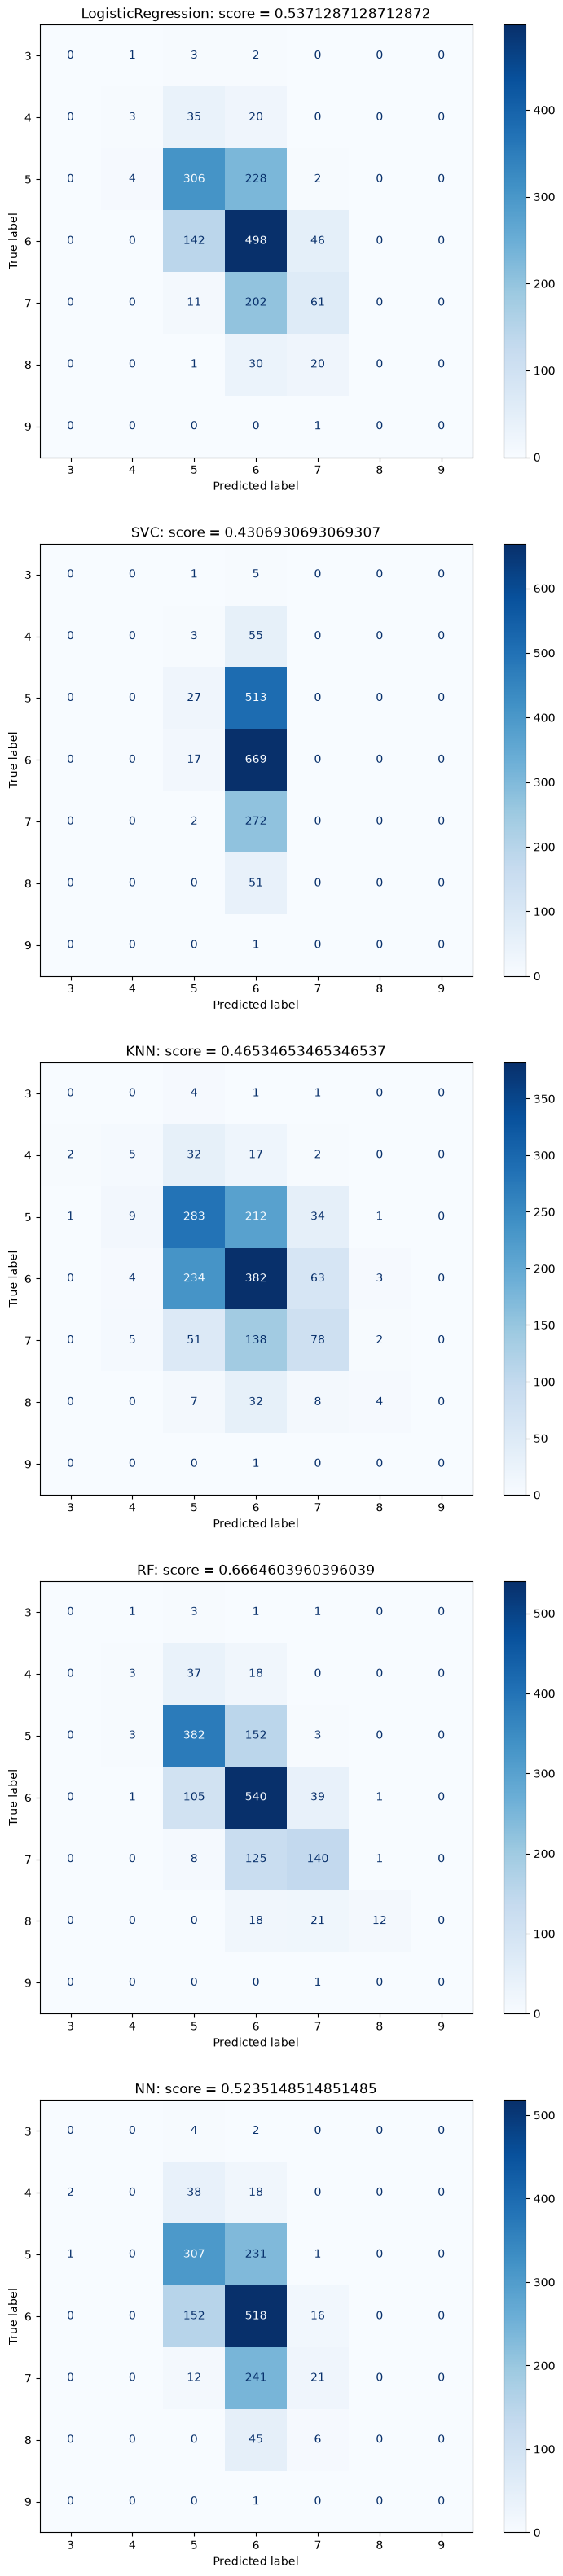

In [7]:
all_scores = pd.DataFrame()
all_scores['without scaling or poly'] = run(df)

## Feature scaling
Feature scaling is the process of transforming numerical features to a common scale. There are several ways to do this, like:
- Normalization -- transform each feature to a range between 0 and 1
- Standardization -- transform each feature to a normal distribution with mean 0 and standard deviation 1
- ...

Not every algorithm needs this. KNN, SVM, logistic regression and neural nets do: a difference of 1 is treated the same on every axis, so a wide column (e.g. sulfur dioxide) dominates a narrow one (e.g. pH). Random forests do not: they split one feature at a time, so changing the units of a column does not change the split.

The original dataset has the following distribution


In [ ]:
df.describe()

Box plots also help with visualization of the distribution

In [ ]:
df.drop(['quality'], axis=1).plot(kind='box', figsize=(20,10))

### Standardization (or Z-score normalization)

Standardization is a technique used to transform numerical features to a normal distribution with mean 0 and standard deviation 1. The idea is to subtract the mean and divide by the standard deviation. The formula is given by
$$ X'_{ij} = \frac{X_{ij}-\mu_j}{\sigma_j}$$
where $X_{ij}$ is the observation $i$ for the feature $j$, $\mu_j$ is the mean and $\sigma_j$ is the standard deviation.


To achieve this, we can use the pandas mean and std methods or call the sklearn StandardScaler method.

Let us now apply the standardization technique

In [ ]:
from sklearn.preprocessing import StandardScaler

# get X and y
X, y = get_X_and_y(df)

# set and fit the scaler
standard_scaler = StandardScaler().fit(X)

# normalize the data
df_std = pd.DataFrame(standard_scaler.transform(X), columns = X.columns)
df_std.plot(kind='box', figsize=(20,5))

df_std['quality'] = y

So, let us create a model but now using the standarderized data

In [ ]:
X.info()

In [ ]:
all_scores['with standardization'] =  run(df_std)

### MinMaxScaler

Another usual solution is to normalize the distribution by subtracting the minimum and dividing by the difference between the maximum and the minimum,

$$ X'_{ij} = \frac{X_{ij}-\min_j}{\max_j-\min_j}$$

where X_{ij} is the observation $i$ for the feature $j$, $\min_j$ is the minimum and $\max_j$ is the maximum. Returned values are in the range [0, 1].

This can be done by coding or simply using sklearn

In [ ]:
from sklearn.preprocessing import MinMaxScaler

X, y = get_X_and_y(df)

# set and fit the scaler
minmax_scaler = MinMaxScaler().fit(X)

df_minmax = pd.DataFrame(minmax_scaler.transform(X), columns = X.columns)
df_minmax.plot(kind='box', figsize=(20,5))

df_minmax['quality'] = y

So, let us create a model but now using the scaled data 

In [ ]:
all_scores['with minmax'] = run(df_minmax)

## Polynomial features

Other approach is to create polynomial features. In this case, if the original set of feature is $(x_1, x_2, \ldots, x_n)$ then the polynomial features with degree 2 are $(1, x_1, x_2, \ldots, x_n, x_1^2, x_1x_2,\ldots,  x_1x_n, x_2^2, \ldots, x_2x_n, ...,  x_n^2 \ldots)$.

Linear models can then fit interactions and curvature that they could not fit with the raw columns. Trees already combine features through successive splits, so the extra columns help them less and can overfit. Expand **after** scaling: otherwise $x^2$ of a large-range column swamps everything else.

This can be done by coding or simply using sklearn


In [ ]:
from sklearn.preprocessing import PolynomialFeatures

X, y = get_X_and_y(df)

# set and fit the scaler
poly = PolynomialFeatures(degree=2).fit(X)

df_poly = pd.DataFrame(poly.transform(X), columns = poly.get_feature_names_out(X.columns))

df_poly.plot(kind='box', figsize=(20,5))

df_poly['quality'] = y

Train a model using the polynomial features

In [ ]:
all_scores['with poly'] = run(df_poly)

## Normalization + Polynomial features

Now, let us combine both normalization and polynomial features

In [ ]:
# get X and y
X, y = get_X_and_y(df)

# set and fit the scaler
standard_scaler = StandardScaler().fit(X)

# normalize the data
df_std = pd.DataFrame(standard_scaler.transform(X), columns = X.columns)

# set and fit the scaler
poly = PolynomialFeatures(degree=2, include_bias=True).fit(df_std)

df_std_poly = pd.DataFrame(poly.transform(df_std), columns = poly.get_feature_names_out(df_std.columns))

df_std_poly.plot(kind='box', figsize=(20,5))

df_std_poly['quality'] = y

And run the model

In [ ]:
all_scores['with standardization and poly'] =  run(df_std_poly)

In [ ]:
all_scores

In [ ]:
all_scores.plot(figsize=(20,8))

## What the table is showing

Scaling and polynomial features are not a free upgrade for every model. Read the table by **row** (the algorithm) as well as by column (the transform).

- **KNN, SVM, logistic regression, MLP.** These models care about scale. After standardization or MinMax, their scores should move. Polynomial features can help the linear ones (logistic regression) by adding products and squares; the MLP already has non-linear activations, so the gain is smaller and easier to overfit.
- **Random forest.** Splits are "is feature $j$ above a threshold?". Standardization and MinMax do not change the order of the values, so RF should look almost flat across those columns. Polynomial features add many correlated columns; a forest can ignore them, but they rarely help as much as they help a linear model.
- **Standardization vs MinMax.** Both put columns on a common footing. Z-score (mean 0, variance 1) is the usual default. MinMax maps to $[0, 1]$ and is sensitive to extreme min/max. Neither replaces a model that was already scale-invariant.
- **Poly after scale.** Combining them is the sound order: scale first, then expand. The last column of the table is that combination, not an extra kind of scaler.
